<a href="https://colab.research.google.com/github/hacaizacr/sp500_trend_classifier/blob/main/Preprocesamiento_de_la_data%2C_selecci%C3%B3n_de_variables_y_modelo_de_regresi%C3%B3n_logistica.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Predicción del rendimiento relativo de empresas del S&P 500 frente a RSP
### Proyecto de Machine Learning · Grupo 2

## Resumen del proyecto
**Pregunta:** dados los indicadores financieros de una empresa del S&P 500, ¿cuál es la probabilidad de que su acción supere al ETF **RSP** (S&P 500 equiponderado) durante los siguientes 12 meses?

**Tipo de problema:** clasificación binaria probabilística. `Target = 1` si la acción superó a RSP, `Target = 0` si no.

**Modelos comparados:** Logistic Regression, Random Forest y XGBoost, con exactamente los mismos datos, la misma separación temporal y las mismas variables.

**Archivos:** `dataset_modelo.csv` (entrenamiento) y `dataset_trazabilidad.csv` (solo para leer las fechas y purgar horizontes solapados; nunca como predictor).

## Decisiones clave

| Decisión | Por qué |
|---|---|
| Separación **cronológica** (train ≤ 2021, test ≥ 2022) | En series de tiempo, una división aleatoria mezclaría el futuro con el pasado y daría resultados artificialmente buenos. |
| **Purga** de horizontes solapados | Una observación de 2021 mide el retorno de los 12 meses siguientes, que caen en 2022. Si se entrena con ella, se usa información del periodo de prueba. |
| **Validación temporal progresiva** | Para elegir hiperparámetros sin tocar el conjunto de prueba: se entrena con años pasados y se valida en el año siguiente. |
| Preprocesamiento **dentro de un Pipeline** | El escalador, el imputador y la winsorización se ajustan solo con datos de entrenamiento (sin fuga). |
| Selección del modelo por **ROC-AUC + Brier + calibración**, no por Accuracy | El objetivo es producir probabilidades confiables, no solo clasificar. |

## Glosario de métricas
- **Accuracy:** % de aciertos con umbral 50 %. Engañosa si las clases no están balanceadas.
- **Precision / Recall / F1:** de los que el modelo dice que superan a RSP, cuántos acierta (precision); de los que realmente superan, cuántos encuentra (recall); F1 combina ambas.
- **ROC-AUC:** capacidad de ordenar: probabilidad de que una acción ganadora reciba mayor probabilidad que una perdedora. 0.5 = azar.
- **Brier Score:** error cuadrático medio de las probabilidades (menor es mejor). Predecir siempre la prevalencia da ≈ 0.25.
- **Calibración / ECE:** si cuando el modelo dice "60 %" realmente ocurre ~60 % de las veces. ECE es la diferencia promedio entre probabilidad predicha y frecuencia real.

## 1. Importaciones y configuración

In [ ]:
import os, json, shutil, warnings, importlib, sys
from datetime import datetime
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV
from sklearn.inspection import permutation_importance
from sklearn.calibration import calibration_curve
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             brier_score_loss, log_loss, average_precision_score, ConfusionMatrixDisplay,
                             classification_report, roc_curve, precision_recall_curve)
from xgboost import XGBClassifier

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid')

SEED = 42                  # semilla única para que los resultados sean reproducibles
np.random.seed(SEED)
ANIO_CORTE = 2021          # entrenamiento: Anio_Obs <= 2021 | prueba: Anio_Obs >= 2022
UMBRAL = 0.5               # umbral de decisión
PURGAR = True              # quitar del entrenamiento las filas cuyo horizonte invade la prueba
ANIOS_VAL = [2017, 2018, 2019, 2020]   # años usados como validación temporal
COLORES = {'Logistic Regression': '#2E86AB', 'Random Forest': '#2E9E5B', 'XGBoost': '#E07A1F'}

def ruta(nombre):
    """Busca el archivo en carpetas habituales; en Colab pide subirlo si no lo encuentra."""
    for d in ['.', '/content', '/content/drive/MyDrive']:
        if os.path.exists(os.path.join(d, nombre)):
            return os.path.join(d, nombre)
    from google.colab import files
    print(f'Sube el archivo {nombre}')
    files.upload()
    return nombre

## 2. Carga y exploración del dataset
**Qué hacemos:** cargar los datos, comprobar que las columnas coinciden con las especificaciones y explorar la distribución del Target y de las variables.

**Qué buscar:** nulos, columnas problemáticas, balance de clases y correlaciones. Una correlación muy alta con Target sería señal de fuga de información.

In [ ]:
df = pd.read_csv(ruta('dataset_modelo.csv'))
TARGET, ANIO = 'Target', 'Anio_Obs'
CONT = ['Revenue_Growth', 'Net_Income', 'Profit_Margin', 'Debt_to_Equity', 'PE_Ratio']   # variables continuas
BIN = ['Patrimonio_Negativo', 'Perdidas']                                                # indicadores 0/1
SECT = [c for c in df.columns if c.startswith('GICS Sector_')]                          # one-hot de sectores
FEATURES = CONT + BIN + SECT                       # Anio_Obs y Target quedan fuera de X
ORDEN = CONT + [c for c in FEATURES if c not in CONT]   # orden de columnas tras el ColumnTransformer
SECTORES = [c.replace('GICS Sector_', '') for c in SECT]
corto = lambda c: c.replace('GICS Sector_', 'Sector: ')

# Verificación automática: no hay columnas extra ni faltantes
assert set(df.columns) == set(FEATURES + [TARGET, ANIO]), 'Las columnas no coinciden con lo esperado'

print('Dimensiones:', df.shape)
print('Nulos totales:', df.isna().sum().sum(), '| Filas duplicadas:', df.duplicated().sum())
print('Cada fila pertenece a un solo sector:', (df[SECT].sum(axis=1) == 1).all())
display(df.dtypes.to_frame('dtype').T)
display(df[CONT].describe().T.round(2))

Dimensiones: (4825, 20)
Nulos totales: 0 | Filas duplicadas: 10
Cada fila pertenece a un solo sector: True


,Anio_Obs,Revenue_Growth,Net_Income,Profit_Margin,Debt_to_Equity,PE_Ratio,Patrimonio_Negativo,Perdidas,GICS Sector_Communication Services,GICS Sector_Consumer Discretionary,GICS Sector_Consumer Staples,GICS Sector_Energy,GICS Sector_Financials,GICS Sector_Health Care,GICS Sector_Industrials,GICS Sector_Information Technology,GICS Sector_Materials,GICS Sector_Real Estate,GICS Sector_Utilities,Target
dtype,int64,float64,float64,float64,float64,float64,int64,int64,int64,int64,int64,int64,int64,int64,int64,int64,int64,int64,int64,int64


,count,mean,std,min,25%,50%,75%,max
Revenue_Growth,4825.0,6.95,18.11,-73.43,-0.37,5.19,11.83,151.83
Net_Income,4825.0,2719.43,5747.39,-10058.40,521.70,1128.00,2655.05,66883.60
Profit_Margin,4825.0,13.10,15.33,-95.65,6.32,11.34,18.21,128.57
Debt_to_Equity,4825.0,1.24,2.18,0.00,0.47,0.70,1.17,28.38
PE_Ratio,4825.0,32.96,55.59,4.07,16.11,23.03,32.72,1044.92


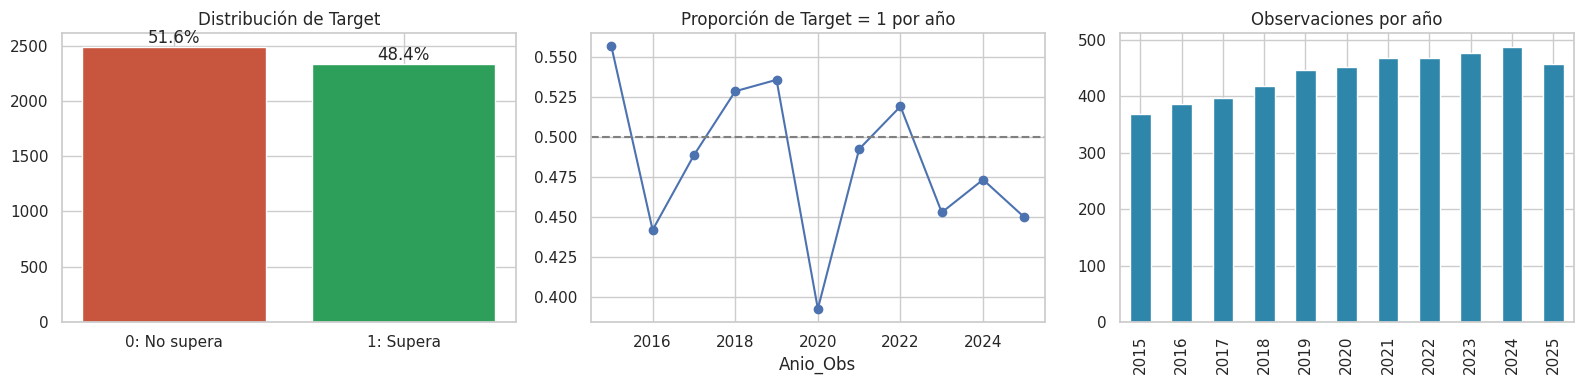

In [ ]:
# Distribución del Target, proporción por año y número de observaciones por año
fig, ax = plt.subplots(1, 3, figsize=(16, 4))

conteo = df[TARGET].value_counts().sort_index()
ax[0].bar(['0: No supera', '1: Supera'], conteo.values, color=['#C8553D', '#2E9E5B'])
for i, v in enumerate(conteo.values):
    ax[0].text(i, v, f'{v / len(df):.1%}', ha='center', va='bottom')
ax[0].set_title('Distribución de Target')

df.groupby(ANIO)[TARGET].mean().plot(marker='o', ax=ax[1])
ax[1].axhline(0.5, color='gray', ls='--'); ax[1].set_title('Proporción de Target = 1 por año')

df[ANIO].value_counts().sort_index().plot.bar(ax=ax[2], color='#2E86AB')
ax[2].set_title('Observaciones por año'); ax[2].set_xlabel('')
plt.tight_layout(); plt.show()

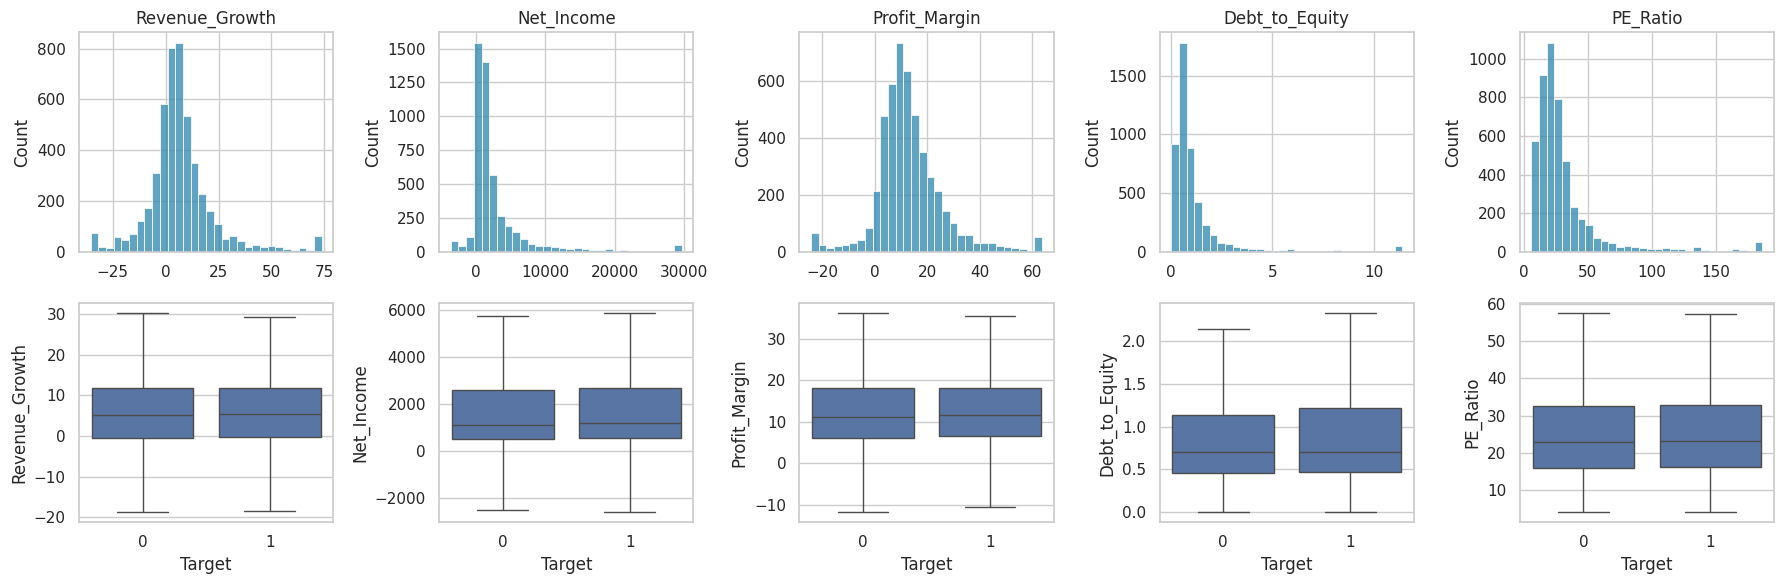

In [ ]:
# Variables continuas: distribución y relación con Target
fig, ax = plt.subplots(2, 5, figsize=(18, 6))
for j, c in enumerate(CONT):
    lo, hi = df[c].quantile([0.01, 0.99])          # recorte solo para graficar
    sns.histplot(df[c].clip(lo, hi), bins=30, ax=ax[0, j], color='#2E86AB'); ax[0, j].set_title(c); ax[0, j].set_xlabel('')
    sns.boxplot(data=df, x=TARGET, y=c, ax=ax[1, j], showfliers=False)
plt.tight_layout(); plt.show()

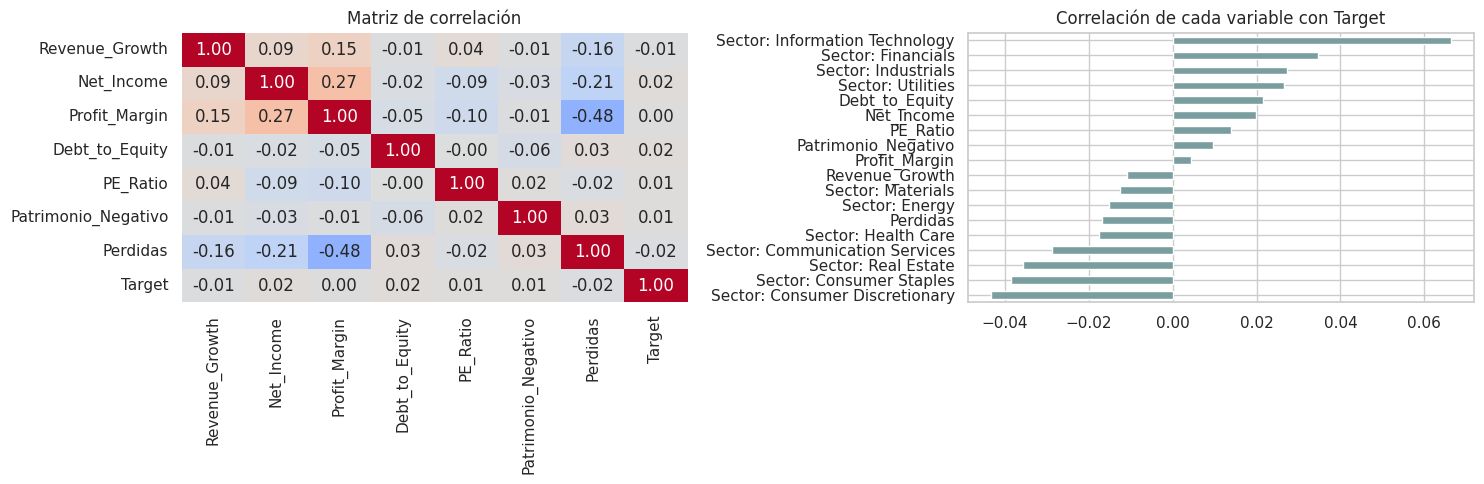

Máxima |correlación| con Target: 0.066  (muy baja: el problema es difícil)


In [ ]:
# Correlaciones: entre variables financieras y de cada variable con Target
fig, ax = plt.subplots(1, 2, figsize=(15, 5))
sns.heatmap(df[CONT + BIN + [TARGET]].corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0, ax=ax[0], cbar=False)
ax[0].set_title('Matriz de correlación')

corr_t = df[FEATURES].corrwith(df[TARGET]).sort_values()
corr_t.rename(index=corto).plot.barh(ax=ax[1], color='#7A9E9F')
ax[1].set_title('Correlación de cada variable con Target')
plt.tight_layout(); plt.show()
print(f'Máxima |correlación| con Target: {corr_t.abs().max():.3f}  (muy baja: el problema es difícil)')

**Lectura:** el Target está casi balanceado (≈ 52 % / 48 %) y todas las correlaciones con Target son muy bajas. Esto es esperable: predecir rendimientos bursátiles es difícil, y un ROC-AUC cercano a 0.55 ya sería realista. Si apareciera un resultado muy superior (≥ 0.80), habría que sospechar de fuga de información.

## 3. Preparación de datos

### 3.1 Revisión de fuga de información en la limpieza previa
| Operación previa | Cómo se hizo | ¿Fuga hacia la prueba? |
|---|---|---|
| Winsorización p1–p99 | Por año de observación | No: cada año usa solo sus propios datos y los años de entrenamiento y prueba son distintos. |
| Imputación de nulos | Mediana de (sector, año) | No, por la misma razón. |
| Sector de empresas fuera del índice | Recuperado de Yahoo Finance | Evita que "estar fuera del índice hoy" sea un predictor. |
| Horizonte de 12 meses | `Fecha_Fin = Fecha_Obs + 365 días` | **Sí hay solapamiento**: filas de 2021 miden retornos de 2022. Se corrige con la purga. |

Los valores originales (antes de winsorizar o imputar) no están en el CSV, por lo que esas operaciones no pueden rehacerse. Como compensación, el *pipeline* vuelve a winsorizar (p1–p99) e imputar (mediana) **dentro de cada fold, solo con datos de entrenamiento**.

### 3.2 Separación cronológica y purga

In [ ]:
# dataset_trazabilidad.csv: solo se leen las fechas (NO se usa como variable predictora)
tz = pd.read_csv(ruta('dataset_trazabilidad.csv'), usecols=['Anio_Obs', 'Target', 'Fecha_Obs', 'Fecha_Fin'],
                 parse_dates=['Fecha_Obs', 'Fecha_Fin'])
assert (tz['Anio_Obs'].values == df[ANIO].values).all() and (tz['Target'].values == df[TARGET].values).all(), \
    'Las filas de ambos archivos no están alineadas'

es_train = df[ANIO] <= ANIO_CORTE                 # separación cronológica, sin azar
inicio_test = tz.loc[~es_train, 'Fecha_Obs'].min()
solapa = es_train & (tz['Fecha_Fin'] >= inicio_test)   # filas de entrenamiento cuyo horizonte llega a la prueba
train_mask = es_train & ~solapa if PURGAR else es_train
test_mask = ~es_train

X_train, y_train = df.loc[train_mask, FEATURES].reset_index(drop=True), df.loc[train_mask, TARGET].reset_index(drop=True)
X_test, y_test = df.loc[test_mask, FEATURES].reset_index(drop=True), df.loc[test_mask, TARGET].reset_index(drop=True)
anio_train = df.loc[train_mask, ANIO].reset_index(drop=True)
anio_test = df.loc[test_mask, ANIO].reset_index(drop=True)
obs_train = tz.loc[train_mask, 'Fecha_Obs'].reset_index(drop=True).values
fin_train = tz.loc[train_mask, 'Fecha_Fin'].reset_index(drop=True).values

print(f'La prueba empieza el {inicio_test.date()}. Filas de entrenamiento purgadas: {int(solapa.sum())}')
display(pd.DataFrame({
    'Filas': [es_train.sum(), len(X_train), len(X_test)],
    '% Target=1': [df.loc[es_train, TARGET].mean(), y_train.mean(), y_test.mean()]},
    index=['Entrenamiento bruto (≤ 2021)', 'Entrenamiento final (tras purga)', 'Prueba (≥ 2022)']).round(3))

La prueba empieza el 2022-01-22. Filas de entrenamiento purgadas: 466


,Filas,% Target=1
Entrenamiento bruto (≤ 2021),2934,0.490
Entrenamiento final (tras purga),2468,0.489
Prueba (≥ 2022),1891,0.474


La purga elimina del entrenamiento las observaciones cuyo horizonte de 12 meses termina después del inicio de la prueba. Esto descarta casi todo 2021: es un costo asumido a cambio de una evaluación limpia (se puede desactivar con `PURGAR = False`).

### 3.3 Validación temporal progresiva
Para elegir hiperparámetros **sin usar la prueba**, se usan 4 folds con ventana expansiva: para validar en el año *5* se entrena con los años anteriores (quitando además las filas cuyo horizonte llega al año *5*).

,n entrenamiento,n validación,% Target=1 (validación)
Año de validación,,,
2017,369,397,0.489
2018,757,418,0.529
2019,1153,446,0.536
2020,1570,451,0.392


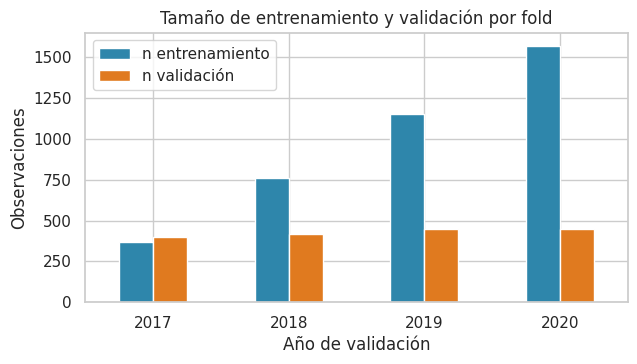

In [ ]:
def splits_temporales(anios, obs, fin, anios_val):
    """Devuelve una lista de (índices de entrenamiento, índices de validación), uno por año de validación."""
    folds = []
    for v in anios_val:
        val = np.where(anios == v)[0]
        inicio_val = obs[val].min()
        train = np.where((anios < v) & (fin < inicio_val))[0]    # años anteriores SIN horizonte solapado
        folds.append((train, val))
    return folds

CV = splits_temporales(anio_train.values, obs_train, fin_train, ANIOS_VAL)
resumen_cv = pd.DataFrame({'n entrenamiento': [len(t) for t, _ in CV], 'n validación': [len(v) for _, v in CV],
                           '% Target=1 (validación)': [y_train.iloc[v].mean() for _, v in CV]}, index=ANIOS_VAL).round(3)
resumen_cv.index.name = 'Año de validación'
display(resumen_cv)
resumen_cv[['n entrenamiento', 'n validación']].plot.bar(figsize=(7, 3.5), color=['#2E86AB', '#E07A1F'])
plt.title('Tamaño de entrenamiento y validación por fold'); plt.ylabel('Observaciones'); plt.xticks(rotation=0); plt.show()

## 4. Preprocesamiento y funciones de apoyo

**Pipeline de preprocesamiento** (se ajusta solo con los datos de entrenamiento de cada fold):
1. `Winsorizer`: recorta las variables continuas a sus percentiles 1 y 99 del entrenamiento.
2. `SimpleImputer`: rellena nulos con la mediana del entrenamiento.
3. `StandardScaler`: estandariza (solo en Logistic Regression; los árboles no lo necesitan).
4. Las variables binarias y one-hot **pasan sin cambios**.

El `Winsorizer` se guarda en un archivo propio (`preprocesamiento.py`) para poder recargar los modelos guardados más adelante.

In [ ]:
codigo_prep = """import numpy as np
from sklearn.base import BaseEstimator, TransformerMixin

class Winsorizer(BaseEstimator, TransformerMixin):
    # Recorta cada columna a los percentiles aprendidos en fit (solo con datos de entrenamiento)
    def __init__(self, lower=0.01, upper=0.99):
        self.lower, self.upper = lower, upper
    def fit(self, X, y=None):
        X = np.asarray(X, float)
        self.lo_ = np.nanquantile(X, self.lower, axis=0)
        self.hi_ = np.nanquantile(X, self.upper, axis=0)
        return self
    def transform(self, X):
        return np.clip(np.asarray(X, float), self.lo_, self.hi_)
"""
with open('preprocesamiento.py', 'w') as f:
    f.write(codigo_prep)
sys.path.insert(0, os.getcwd()); importlib.invalidate_caches()
from preprocesamiento import Winsorizer

def build_pipeline(modelo, escalar):
    """Preprocesamiento de las variables continuas + modelo, todo en un único Pipeline."""
    pasos = [('winsor', Winsorizer()), ('imputer', SimpleImputer(strategy='median'))]
    if escalar:
        pasos.append(('scaler', StandardScaler()))
    pre = ColumnTransformer([('num', Pipeline(pasos), CONT)], remainder='passthrough')   # binarias y sectores intactos
    return Pipeline([('pre', pre), ('model', modelo)])

In [ ]:
SCORING = {'roc_auc': 'roc_auc', 'brier': 'neg_brier_score'}   # se miden ambas; se elige por ROC-AUC

def buscar(pipe, grid, n_iter=None):
    """Búsqueda de hiperparámetros con la validación temporal CV. Se evalúa en folds, nunca en la prueba."""
    if n_iter:
        s = RandomizedSearchCV(pipe, grid, n_iter=n_iter, cv=CV, scoring=SCORING, refit='roc_auc', n_jobs=-1, random_state=SEED)
    else:
        s = GridSearchCV(pipe, grid, cv=CV, scoring=SCORING, refit='roc_auc', n_jobs=-1)
    return s.fit(X_train, y_train)

def tabla_cv(s, top=8):
    """Las mejores configuraciones según el AUC medio de validación."""
    r = pd.DataFrame(s.cv_results_)
    t = pd.DataFrame({'AUC medio': r['mean_test_roc_auc'], 'AUC desv.': r['std_test_roc_auc'], 'Brier medio': -r['mean_test_brier'],
                      'Parámetros': [', '.join(f"{k.replace('model__', '')}={v}" for k, v in p.items()) for p in r['params']]})
    return t.sort_values('AUC medio', ascending=False).head(top).round(4).reset_index(drop=True)

def grafico_cv(s, nombre):
    """AUC de la mejor configuración en cada año de validación."""
    i = s.best_index_
    auc = [s.cv_results_[f'split{k}_test_roc_auc'][i] for k in range(len(CV))]
    plt.figure(figsize=(6, 3.5))
    plt.bar([str(a) for a in ANIOS_VAL], auc, color=COLORES[nombre]); plt.axhline(0.5, color='gray', ls='--')
    plt.ylim(0.4, max(auc) + 0.05); plt.title(f'{nombre}: AUC por año de validación (línea = azar)'); plt.show()

In [ ]:
def ece_score(y, p, bins=10):
    """Error de calibración esperado: diferencia media entre probabilidad predicha y frecuencia real."""
    orden = np.argsort(p); y, p = np.asarray(y)[orden], np.asarray(p)[orden]
    grupos = np.array_split(np.arange(len(p)), bins)
    return sum(len(g) / len(p) * abs(y[g].mean() - p[g].mean()) for g in grupos)

def pendiente_calibracion(y, p):
    """Pendiente de la regresión de y sobre logit(p): 1 = calibrado, <1 = sobreconfiado."""
    q = np.clip(p, 1e-6, 1 - 1e-6)
    return LogisticRegression(C=1e6).fit(np.log(q / (1 - q)).reshape(-1, 1), y).coef_[0, 0]

def metricas(y, p):
    y = np.asarray(y); pred = (p >= UMBRAL).astype(int)
    return {'Accuracy': accuracy_score(y, pred), 'Precision': precision_score(y, pred, zero_division=0),
            'Recall': recall_score(y, pred, zero_division=0), 'F1-Score': f1_score(y, pred, zero_division=0),
            'ROC-AUC': roc_auc_score(y, p), 'Brier Score': brier_score_loss(y, p), 'PR-AUC': average_precision_score(y, p),
            'Log-Loss': log_loss(y, p), 'ECE': ece_score(y, p), 'Pendiente calibración': pendiente_calibracion(y, p)}

In [ ]:
def graficos_evaluacion(nombre, y, p):
    """Seis gráficos estándar de evaluación sobre el conjunto de prueba."""
    y = np.asarray(y); color = COLORES[nombre]
    fig, ax = plt.subplots(2, 3, figsize=(16, 9)); ax = ax.ravel()

    ConfusionMatrixDisplay.from_predictions(y, (p >= UMBRAL).astype(int), ax=ax[0], cmap='Blues', colorbar=False,
                                            display_labels=['No supera', 'Supera'])
    ax[0].set_title('Matriz de confusión'); ax[0].grid(False)

    fpr, tpr, _ = roc_curve(y, p)
    ax[1].plot(fpr, tpr, color=color, label=f'AUC = {roc_auc_score(y, p):.3f}'); ax[1].plot([0, 1], [0, 1], 'k--', label='Azar')
    ax[1].set(title='Curva ROC', xlabel='Falsos positivos', ylabel='Verdaderos positivos'); ax[1].legend()

    prec, rec, _ = precision_recall_curve(y, p)
    ax[2].plot(rec, prec, color=color, label=f'AP = {average_precision_score(y, p):.3f}'); ax[2].axhline(y.mean(), color='k', ls='--', label='Prevalencia')
    ax[2].set(title='Curva Precision-Recall', xlabel='Recall', ylabel='Precision'); ax[2].legend()

    real, pred_media = calibration_curve(y, p, n_bins=8, strategy='quantile')
    ax[3].plot(pred_media, real, 'o-', color=color, label=f'ECE = {ece_score(y, p):.3f}'); ax[3].plot([0, 1], [0, 1], 'k--', label='Calibración perfecta')
    ax[3].set(title='Curva de calibración', xlabel='Probabilidad predicha', ylabel='Frecuencia real'); ax[3].legend()

    ax[4].hist(p[y == 0], bins=25, alpha=.6, color='#C8553D', label='No superó a RSP', density=True)
    ax[4].hist(p[y == 1], bins=25, alpha=.6, color='#2E9E5B', label='Superó a RSP', density=True)
    ax[4].axvline(UMBRAL, color='k', ls='--'); ax[4].set(title='Distribución de probabilidades predichas', xlabel='P(supera a RSP)'); ax[4].legend()

    t = pd.DataFrame({'Predicha': p, 'Real': y})
    t['Quintil'] = pd.qcut(t['Predicha'].rank(method='first'), 5, labels=[1, 2, 3, 4, 5])     # 5 = mayor probabilidad
    g = t.groupby('Quintil').mean()
    g.plot.bar(ax=ax[5], color=[color, 'gray'], rot=0)
    ax[5].set(title='Probabilidad predicha vs resultado real por quintil', ylim=(g.min().min() - .05, g.max().max() + .05))
    ax[5].set_xlabel('Quintil de probabilidad predicha')

    plt.suptitle(f'{nombre}: evaluación en prueba (2022-2025)', fontsize=13, fontweight='bold'); plt.tight_layout(); plt.show()

RES = {}   # aquí se guardan pipeline, probabilidades y métricas de cada modelo

def reporte_modelo(nombre, search):
    """Evalúa el mejor modelo de la búsqueda en el conjunto de prueba y guarda los resultados."""
    pipe = search.best_estimator_
    p = pipe.predict_proba(X_test)[:, 1]
    m = metricas(y_test, p)
    cv_auc = search.cv_results_['mean_test_roc_auc'][search.best_index_]
    RES[nombre] = {'pipe': pipe, 'p': p, 'm': m, 'params': search.best_params_, 'cv_auc': cv_auc}
    print('Mejores hiperparámetros:', search.best_params_)
    print(f'AUC entrenamiento: {roc_auc_score(y_train, pipe.predict_proba(X_train)[:, 1]):.3f} | '
          f'AUC validación temporal: {cv_auc:.3f} | AUC prueba: {m["ROC-AUC"]:.3f}')
    display(pd.Series(m, name=nombre).round(4).to_frame())
    print(classification_report(y_test, (p >= UMBRAL).astype(int), target_names=['No supera RSP', 'Supera RSP'], zero_division=0))
    graficos_evaluacion(nombre, y_test, p)

def grafico_importancias(nombre, pipe, nativa, titulo):
    """Importancia propia del modelo (izquierda) y por permutación en prueba (derecha). Devuelve la de permutación."""
    r = permutation_importance(pipe, X_test, y_test, scoring='roc_auc', n_repeats=30, random_state=SEED, n_jobs=-1)
    perm = pd.DataFrame({'media': r.importances_mean, 'std': r.importances_std}, index=FEATURES)
    fig, ax = plt.subplots(1, 2, figsize=(15, 5))
    nativa.reindex(nativa.abs().sort_values().index).tail(10).rename(index=corto).plot.barh(ax=ax[0], color=COLORES[nombre])
    ax[0].set_title(titulo)
    perm['media'].sort_values().tail(10).rename(index=corto).plot.barh(ax=ax[1], color=COLORES[nombre], alpha=.7)
    ax[1].set_title('Importancia por permutación (caída del AUC en prueba)')
    plt.suptitle(f'{nombre}: variables más influyentes', fontweight='bold'); plt.tight_layout(); plt.show()
    return perm

**Importancia por permutación:** se desordena una variable a la vez y se mide cuánto cae el ROC-AUC. Si la caída es ≈ 0, el modelo no obtiene información útil de esa variable. Se calcula sobre prueba solo para **interpretar**, nunca para elegir hiperparámetros.

## 5. Logistic Regression
**Idea:** modelo lineal que estima la probabilidad con la función logística. Es simple, interpretable y sirve de referencia.

**Hiperparámetros evaluados** (con validación temporal, sin usar la prueba):
- `C`: inverso de la regularización L2 (más pequeño = más regularización = modelo más simple).
- `class_weight`: `None` o `balanced` (dar más peso a la clase minoritaria).

,AUC medio,AUC desv.,Brier medio,Parámetros
0,0.5142,0.0481,0.2636,"C=10.0, class_weight=balanced"
1,0.5141,0.0483,0.2647,"C=100.0, class_weight=None"
2,0.5141,0.0481,0.2639,"C=31.622776601683793, class_weight=balanced"
3,0.5141,0.0481,0.2639,"C=100.0, class_weight=balanced"
4,0.5140,0.0483,0.2646,"C=31.622776601683793, class_weight=None"
5,0.5139,0.0483,0.2644,"C=10.0, class_weight=None"
6,0.5138,0.0481,0.2630,"C=3.1622776601683795, class_weight=balanced"
7,0.5136,0.0483,0.2638,"C=3.1622776601683795, class_weight=None"


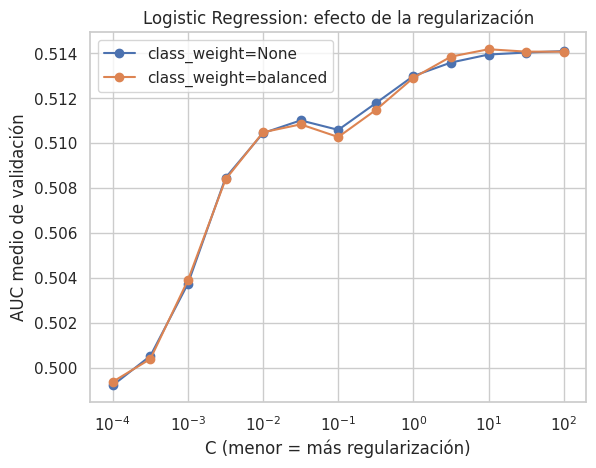

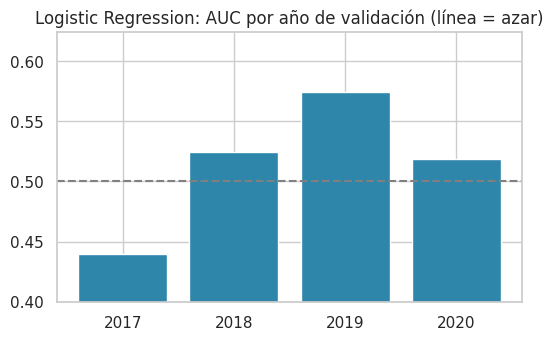

In [ ]:
pipe_lr = build_pipeline(LogisticRegression(max_iter=5000, random_state=SEED), escalar=True)
grid_lr = {'model__C': np.logspace(-4, 2, 13), 'model__class_weight': [None, 'balanced']}
search_lr = buscar(pipe_lr, grid_lr)
display(tabla_cv(search_lr))

# AUC de validación según la regularización
r = pd.DataFrame(search_lr.cv_results_)
for cw in [None, 'balanced']:
    s = r[r['param_model__class_weight'].astype(str) == str(cw)].sort_values('param_model__C')
    plt.semilogx(s['param_model__C'].astype(float), s['mean_test_roc_auc'], 'o-', label=f'class_weight={cw}')
plt.xlabel('C (menor = más regularización)'); plt.ylabel('AUC medio de validación'); plt.legend(); plt.title('Logistic Regression: efecto de la regularización')
plt.show()
grafico_cv(search_lr, 'Logistic Regression')

Mejores hiperparámetros: {'model__C': np.float64(10.0), 'model__class_weight': 'balanced'}
AUC entrenamiento: 0.598 | AUC validación temporal: 0.514 | AUC prueba: 0.515


,Logistic Regression
Accuracy,0.5040
Precision,0.4764
Recall,0.4721
F1-Score,0.4742
ROC-AUC,0.5155
Brier Score,0.2575
PR-AUC,0.4963
Log-Loss,0.7103
ECE,0.0903
Pendiente calibración,0.0831


               precision    recall  f1-score   support

No supera RSP       0.53      0.53      0.53       995
   Supera RSP       0.48      0.47      0.47       896

     accuracy                           0.50      1891
    macro avg       0.50      0.50      0.50      1891
 weighted avg       0.50      0.50      0.50      1891



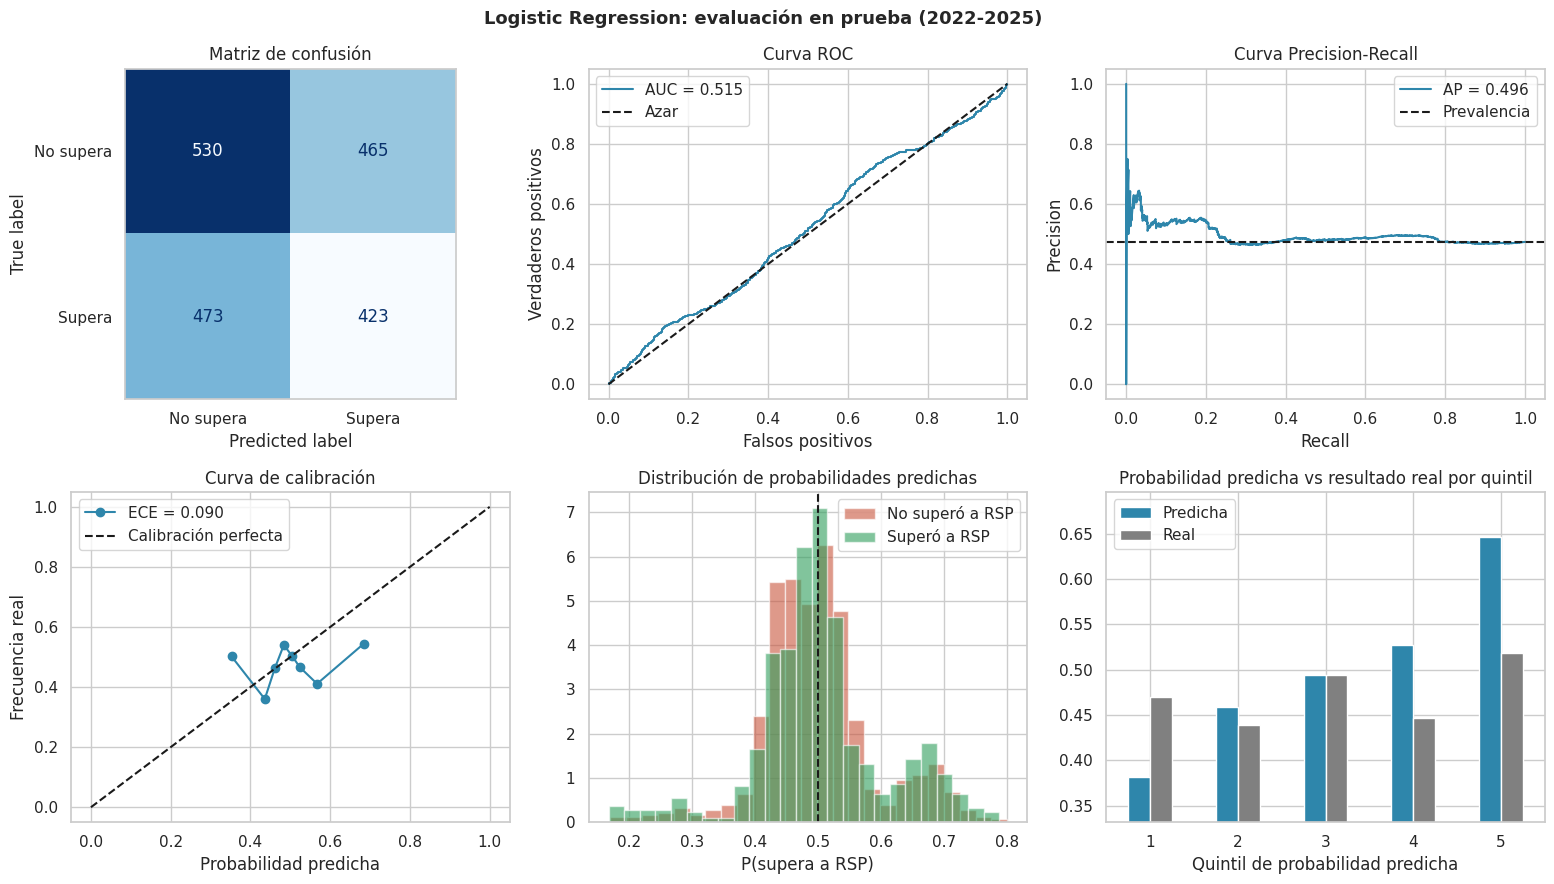

In [ ]:
reporte_modelo('Logistic Regression', search_lr)

**Cómo leer las gráficas de evaluación:**
- *Matriz de confusión:* aciertos y errores con umbral 50 %.
- *Curva ROC:* cuanto más alejada de la diagonal (azar), mejor ordena el modelo.
- *Curva de calibración:* si los puntos siguen la diagonal, las probabilidades son confiables.
- *Quintiles:* si el modelo funcionara, la tasa real debería subir de Q1 a Q5.

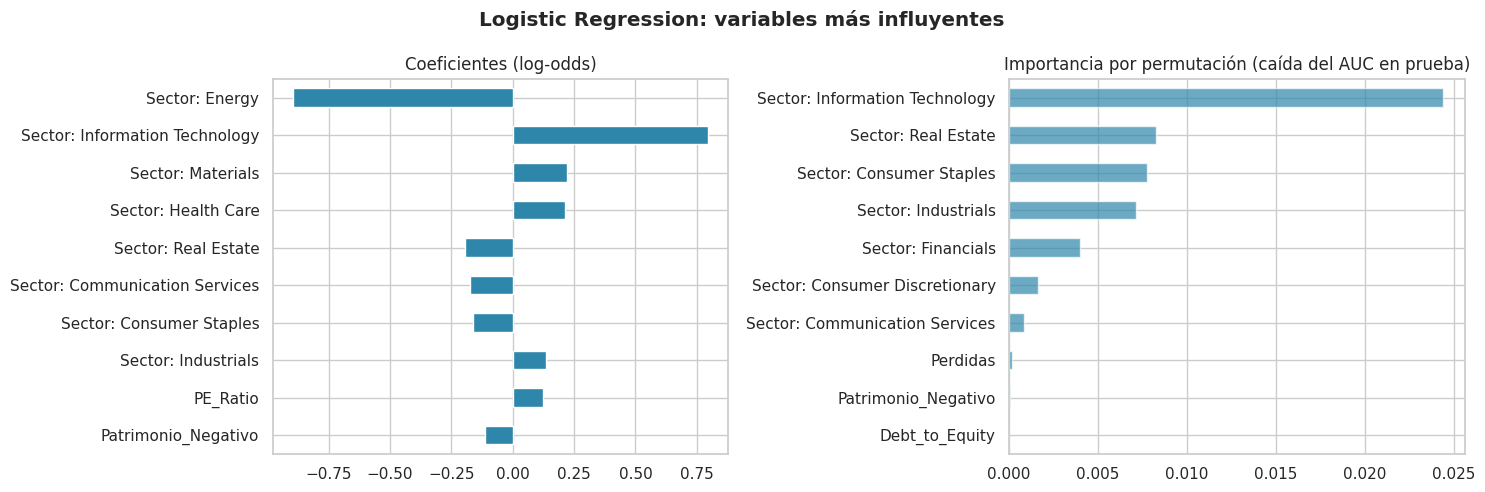

,Coeficiente,Odds ratio
Sector: Energy,-0.894,0.409
Sector: Information Technology,0.794,2.213
Sector: Materials,0.222,1.249
Sector: Health Care,0.214,1.239
Sector: Real Estate,-0.196,0.822
Sector: Communication Services,-0.175,0.839
Sector: Consumer Staples,-0.164,0.849
Sector: Industrials,0.137,1.147


- Sector: Energy: reduce la probabilidad de superar a RSP (odds ratio = 0.41)
- Sector: Information Technology: aumenta la probabilidad de superar a RSP (odds ratio = 2.21)
- Sector: Materials: aumenta la probabilidad de superar a RSP (odds ratio = 1.25)
- Sector: Health Care: aumenta la probabilidad de superar a RSP (odds ratio = 1.24)
- Sector: Real Estate: reduce la probabilidad de superar a RSP (odds ratio = 0.82)


In [ ]:
# Coeficientes (variables continuas estandarizadas, por lo que son comparables) y odds ratio
coef = pd.Series(search_lr.best_estimator_.named_steps['model'].coef_[0], index=ORDEN)
perm_lr = grafico_importancias('Logistic Regression', search_lr.best_estimator_, coef, 'Coeficientes (log-odds)')

tabla_coef = pd.DataFrame({'Coeficiente': coef, 'Odds ratio': np.exp(coef)}).sort_values('Coeficiente', key=abs, ascending=False)
display(tabla_coef.head(8).rename(index=corto).round(3))
for variable, fila in tabla_coef.head(5).iterrows():
    efecto = 'aumenta' if fila['Coeficiente'] > 0 else 'reduce'
    print(f'- {corto(variable)}: {efecto} la probabilidad de superar a RSP (odds ratio = {fila["Odds ratio"]:.2f})')

**Interpretación.** El signo del coeficiente indica la dirección del efecto (manteniendo el resto constante) y el odds ratio su magnitud: 1.5 significa que las probabilidades de superar a RSP aumentan 50 %; 0.5 que se reducen a la mitad. Si la importancia por permutación es cercana a cero, el modelo apenas obtiene capacidad predictiva fiable de esa variable.

**Limitaciones.** Supone relaciones lineales (en log-odds) y no captura interacciones; los datos financieros tienen colas pesadas y la señal es débil, por lo que se esperan métricas cercanas al azar.